# 02. Przygotowanie danych

Cel: zamienić surowe EKG na dane gotowe do treningu i sprawdzić, że każdy krok działa poprawnie.

1. Wybór zapisów i podział na zbiory
2. Normalizacja
3. Wagi klas
4. Gotowy zbiór: `load_dataset()`
5. Warianty do eksperymentów: mniejszy zbiór, szum etykiet, szum sygnału
6. Podsumowanie

Cała logika jest w `src/preprocessing.py`, a ten notebook ją pokazuje i sprawdza.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data import CLASSES, LEADS, load_metadata, load_signals
from src.preprocessing import (CLIP_MV, add_label_noise, add_signal_noise, class_weights,
                               fit_normalizer, load_dataset, normalize, single_label, subsample)

sns.set_theme(style="whitegrid")

/opt/homebrew/Caskroom/miniconda/base/envs/prob-clf/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Wybór zapisów i podział na zbiory

Bierzemy zapisy z dokładnie jedną nadklasą. **Nie filtrujemy po pewności diagnozy ani jakości sygnału**:
niepewne i zaszumione zapisy są potrzebne do analizy niepewności.

In [2]:
meta = single_label(load_metadata())
X_raw = load_signals(meta)

counts = pd.crosstab(meta.label, meta.split).loc[CLASSES, ["train", "val", "test"]]
counts.loc["razem"] = counts.sum()
counts

split,train,val,test
label,,,
NORM,7254,916,913
MI,2048,234,256
STTC,1907,256,243
CD,1353,172,184
HYP,416,64,56
razem,12978,1642,1652


## 2. Normalizacja

Dwa kroki:
1. **przycięcie** wartości do ±5 mV, żeby artefakty (do ±20 mV) nie zdominowały skali,
2. **standaryzacja każdego odprowadzenia**: $x' = (x - \mu) / \sigma$, ze statystykami liczonymi **tylko na zbiorze treningowym**.

Nie normalizujemy każdego zapisu osobno, bo amplituda niesie informację diagnostyczną (np. wysoki woltaż przy przeroście, HYP).

In [3]:
train_mask = (meta.split == "train").to_numpy()
mu, sigma = fit_normalizer(X_raw[train_mask])
pd.DataFrame({"średnia [mV]": mu, "odch. std [mV]": sigma}, index=LEADS).round(4).T

,I,II,III,aVR,aVL,aVF,V1,V2,V3,V4,V5,V6
średnia [mV],-0.0022,-0.0017,0.0005,0.0020,-0.0013,-0.0005,0.0002,-0.0010,-0.0017,-0.0014,-0.0007,-0.0017
odch. std [mV],0.1599,0.1557,0.1526,0.1389,0.1355,0.1325,0.2140,0.3163,0.3063,0.2778,0.2538,0.2283


In [4]:
clipped = np.abs(X_raw) > CLIP_MV
print(f"Przyciętych wartości: {clipped.mean():.5%}")
print(f"Zapisów z co najmniej jedną przyciętą wartością: {clipped.any(axis=(1, 2)).sum()} z {len(meta)}")

Przyciętych wartości: 0.00629%
Zapisów z co najmniej jedną przyciętą wartością: 154 z 16272


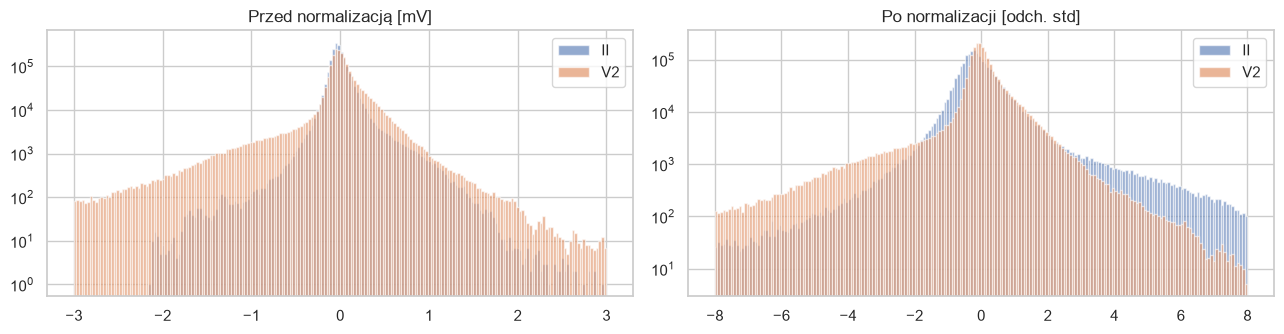

In [5]:
X_norm = normalize(X_raw, mu, sigma)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
sample = np.random.default_rng(0).choice(len(meta), 2000, replace=False)
for i in [1, 7]:  # II i V2
    axes[0].hist(X_raw[sample, :, i].ravel(), bins=200, range=(-3, 3), alpha=0.6, label=LEADS[i])
    axes[1].hist(X_norm[sample, :, i].ravel(), bins=200, range=(-8, 8), alpha=0.6, label=LEADS[i])
axes[0].set(title="Przed normalizacją [mV]", yscale="log")
axes[1].set(title="Po normalizacji [odch. std]", yscale="log")
for ax in axes:
    ax.legend()
plt.tight_layout()

In [6]:
# Po normalizacji: średnia ~0 i odchylenie ~1 w każdym zbiorze (test i walidacja tylko w przybliżeniu)
pd.DataFrame({
    split: [X_norm[(meta.split == split).to_numpy()].mean(), X_norm[(meta.split == split).to_numpy()].std()]
    for split in ["train", "val", "test"]
}, index=["średnia", "odch. std"]).round(3)

,train,val,test
średnia,-0.0,0.001,0.001
odch. std,1.0,0.981,0.983


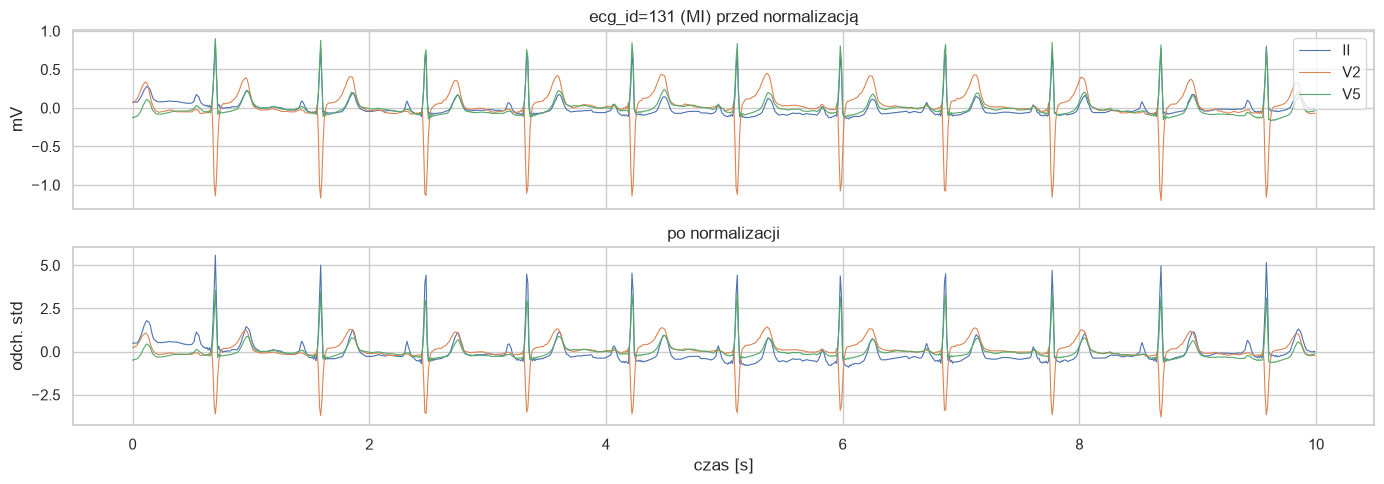

In [7]:
ecg_id = meta[(meta.label == "MI") & ~meta.noisy].index[0]
row = meta.index.get_loc(ecg_id)
t = np.arange(X_raw.shape[1]) / 100
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for i in [1, 7, 10]:
    axes[0].plot(t, X_raw[row, :, i], lw=0.8, label=LEADS[i])
    axes[1].plot(t, X_norm[row, :, i], lw=0.8, label=LEADS[i])
axes[0].set(ylabel="mV", title=f"ecg_id={ecg_id} (MI) przed normalizacją")
axes[1].set(ylabel="odch. std", title="po normalizacji", xlabel="czas [s]")
axes[0].legend(loc="upper right")
plt.tight_layout()

## 3. Wagi klas

$w_c = \left(\frac{N}{K \cdot N_c}\right)^{p}$, gdzie $p = 1$ to pełne wagi, $p = 0{,}5$ łagodniejsze, a $p = 0$ brak wag.

Wagi przesuwają prawdopodobieństwa modelu, więc wpływają na kalibrację. **Oba modele trenujemy z tym samym ustawieniem.**

In [8]:
y_train = meta.loc[meta.split == "train", "label_idx"].to_numpy()
pd.DataFrame({
    "przykładów": np.bincount(y_train),
    "pełne (p=1)": class_weights(y_train, 1.0).values(),
    "łagodne (p=0.5)": class_weights(y_train, 0.5).values(),
}, index=CLASSES).round(2)

,przykładów,pełne (p=1),łagodne (p=0.5)
NORM,7254,0.36,0.60
MI,2048,1.27,1.13
STTC,1907,1.36,1.17
CD,1353,1.92,1.39
HYP,416,6.24,2.50


## 4. Gotowy zbiór: `load_dataset()`

Jedna funkcja zwraca znormalizowane `X`, etykiety `y` i metadane `meta` dla każdego zbioru, w tej samej kolejności.
Metadane (m.in. `likelihood`, `noisy`) są potrzebne dopiero przy ewaluacji.

In [9]:
data = load_dataset()

pd.DataFrame({
    split: {"X": data[split]["X"].shape, "y": data[split]["y"].shape, "dtype": data[split]["X"].dtype,
            "MB": round(data[split]["X"].nbytes / 1e6)}
    for split in ["train", "val", "test"]
}).T

,X,y,dtype,MB
train,"(12978, 1000, 12)","(12978,)",float32,623
val,"(1642, 1000, 12)","(1642,)",float32,79
test,"(1652, 1000, 12)","(1652,)",float32,79


In [10]:
# Kontrole poprawności
for split in ["train", "val", "test"]:
    d = data[split]
    assert len(d["X"]) == len(d["y"]) == len(d["meta"])
    assert (d["meta"].label_idx.to_numpy() == d["y"]).all()
    assert np.isfinite(d["X"]).all()
assert not set(data["train"]["meta"].patient_id) & set(data["test"]["meta"].patient_id)
assert np.allclose(data["mu"], mu) and np.allclose(data["sigma"], sigma)

# Ten sam zapis w load_dataset() i w ręcznej normalizacji
ecg_id = data["test"]["meta"].index[0]
assert np.allclose(data["test"]["X"][0], X_norm[meta.index.get_loc(ecg_id)])
print("Wszystkie kontrole OK")

Wszystkie kontrole OK


## 5. Warianty do eksperymentów

### Mniejszy zbiór treningowy

`load_dataset(n_train=..., seed=...)` losuje podzbiór treningowy z zachowaniem proporcji klas.
Walidacja, test i normalizacja się nie zmieniają.

In [11]:
train_meta = meta[meta.split == "train"]
sizes = [500, 1000, 2000, 5000, None]
pd.DataFrame({
    (n or "pełny"): subsample(train_meta, n, seed=0).label.value_counts().reindex(CLASSES)
    for n in sizes
})

,500,1000,2000,5000,pełny
label,,,,,
NORM,279,559,1118,2795,7254
MI,79,158,316,789,2048
STTC,73,147,294,735,1907
CD,52,104,209,521,1353
HYP,16,32,64,160,416


### Szum etykiet

`add_label_noise(y, rate)` zamienia etykietę wybranego odsetka przykładów na inną, losową klasę. Stosujemy go tylko do zbioru treningowego.

In [12]:
y = data["train"]["y"]
rows = []
for rate in [0.0, 0.1, 0.2, 0.3]:
    noisy_y = add_label_noise(y, rate, seed=0)
    rows.append({"zadany odsetek": rate, "zmienionych etykiet": round((noisy_y != y).mean(), 3)})
pd.DataFrame(rows)

,zadany odsetek,zmienionych etykiet
0,0.0,0.000
1,0.1,0.103
2,0.2,0.202
3,0.3,0.297


### Szum sygnału

`add_signal_noise(X, sigma)` dodaje szum gaussowski do znormalizowanego sygnału.
`sigma` jest w jednostkach odchylenia standardowego odprowadzenia, czyli 0,5 to szum o połowie typowej amplitudy.

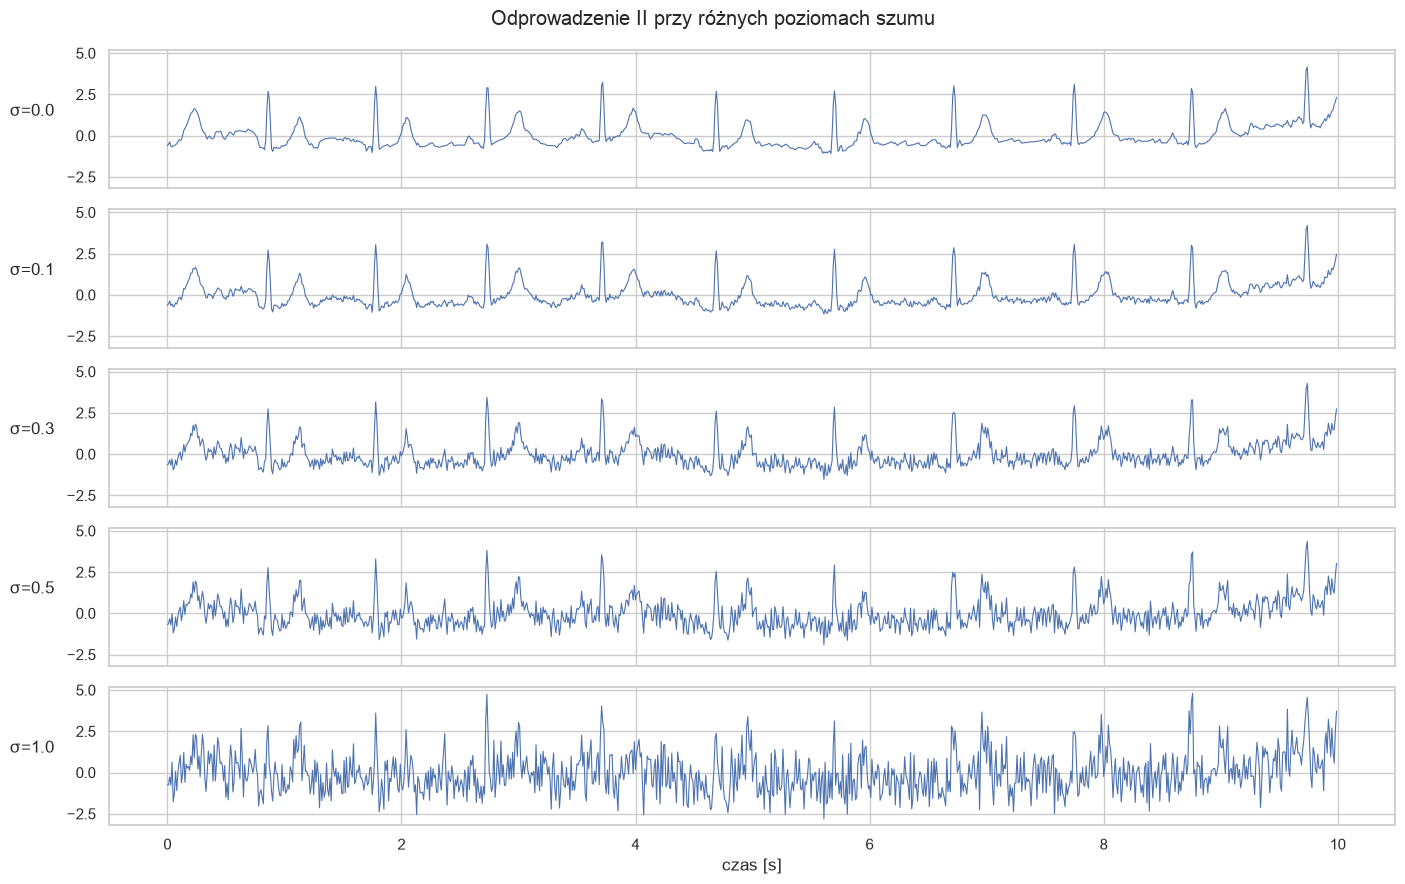

In [13]:
x = data["test"]["X"][0]
t = np.arange(x.shape[0]) / 100
levels = [0.0, 0.1, 0.3, 0.5, 1.0]
fig, axes = plt.subplots(len(levels), 1, figsize=(14, 9), sharex=True, sharey=True)
for ax, s in zip(axes, levels):
    ax.plot(t, add_signal_noise(x, s, seed=0)[:, 1], lw=0.8)
    ax.set_ylabel(f"σ={s}", rotation=0, labelpad=25)
axes[-1].set_xlabel("czas [s]")
fig.suptitle("Odprowadzenie II przy różnych poziomach szumu")
plt.tight_layout()

## 6. Podsumowanie

| Krok | Ustawienie |
|---|---|
| Zapisy | jedna nadklasa, 16 272 zapisów, bez filtrowania po pewności i jakości |
| Podział | `strat_fold`: 1–8 trening (12 978), 9 walidacja (1 642), 10 test (1 652), bez wspólnych pacjentów |
| Normalizacja | przycięcie do ±5 mV, standaryzacja każdego odprowadzenia statystykami treningowymi |
| Wagi klas | `class_weights(y, power)`, to samo ustawienie dla obu modeli |
| Eksperymenty | `load_dataset(n_train, seed)`, `add_label_noise`, `add_signal_noise` |

Użycie w kolejnych notebookach:

```python
from src.preprocessing import load_dataset, class_weights

data = load_dataset()                      # albo load_dataset(n_train=1000, seed=0)
X_train, y_train = data["train"]["X"], data["train"]["y"]
X_val, y_val = data["val"]["X"], data["val"]["y"]
weights = class_weights(y_train, power=1.0)
```